# Class 12: Multiple testing

This class notebook is designed to let you practice the basics of multiple testing. 

Everything you need to complete these analyses is covered in today's lecture and the accompanying workflow notebooks. The workflow notebooks work through the examples in the lecture in more detail. You should use those as a reference to completing the analyses in this notebook.

There are three questions in this notebook:

1. **Can light shone on knees reset your circadian clock?** In this question we compare each treatment to a control, so the Holm method of multiple testing is best.
2. **How does caffeine in nectar affect visitation by pollinators?**: In this question we want to compare each treatment to every other treatment. This is called **pairwise** testing, for which the Holm method is used.
3. **Cancer drug screening**. In this question we are screening for potential potent cancer drugs, so a Benjamini-Hochberg test is appropriate.

## Imports

In [5]:
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import ttest_ind
from itertools import combinations
from statsmodels.formula.api import ols
from statsmodels.stats.oneway import anova_oneway
from statsmodels.stats.multitest import multipletests

# **Question 1:** Can light shone on knees reset your circadian clock?

<div>
<img src="Images/circadian.jpg" width='50%' title=""/>
</div>

A scientific paper published in 1998 (Campbell and Murphy 1998) reported that the circadian clock of people with jetlag can be reset by shining light on the backs of their knees. A later paper (Wright and Czeisler 2002) re-examined this controversial result. The new experiment measured the phase shift in the circadian cycle of people woken from sleep and subjected to one of three interventions: 1) Light shone in eyes only, 2) light shone on backs of knees only, or 3) no light shone at all. This last intervention is the control group against which the other two interventions were compared. The phase shifts in the volunteers' circadian clocks were measured after two days of intervention.

The data are in the file `../Datasets/knees.csv`. The variable `shift` is the phase shift measured in hours.

<div class="alert alert-warning">

Use the [workflow_plant_growth.ipynb](workflow_plant_growth.ipynb) notebook to help you answer this question.
</div>

- Read in the data and print it to see what it looks like.

In [8]:
knees = pd.read_csv('../Datasets/knees.csv')
knees

,treatment,shift
0,control,0.53
1,control,0.36
2,control,0.20
3,control,-0.37
4,control,-0.60
5,control,-0.64
6,control,-0.68
7,control,-1.27
8,knee,0.73
9,knee,0.31


- Use an appropriate graph to visually examine the relationship between light treatment and phase shift. 

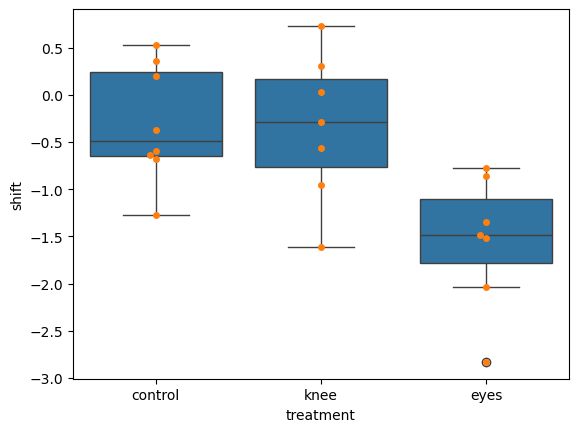

In [10]:
sns.boxplot(x='treatment', y='shift', data=knees);
sns.swarmplot(x='treatment', y='shift', data=knees);


- Perform an ANOVA "omnibus" test to determine the compatibility of the data with the null hypothesis that the means of all groups are the same. You can use either `anova_oneway` or a linear model, they will both give the same answer.

<div class="alert alert-info">

Answer

- *F*<sub>2,19</sub> = 7.3
- *P* = 0.0045
</div>

In [12]:
test = anova_oneway(knees['shift'], knees['treatment'], use_var='equal')
print(test.df)
print(test.statistic)
print(test.pvalue)

(2.0, 19.0)
7.289448655442485
0.004472271090001116


In [13]:
formula = 'shift ~ treatment'
fit = ols(formula, knees).fit()
fit.summary().tables[0]

Dep. Variable:,shift,R-squared:,0.434
Model:,OLS,Adj. R-squared:,0.375
Method:,Least Squares,F-statistic:,7.289
Date:,"Thu, 29 Oct 2026",Prob (F-statistic):,0.00447
Time:,16:17:39,Log-Likelihood:,-21.881
No. Observations:,22,AIC:,49.76
Df Residuals:,19,BIC:,53.03
Df Model:,2,,
Covariance Type:,nonrobust,,


The ANOVA tells you that at least one of the means is different from at least one of the others. You should now compare each treatment to the control to see which are significantly different from it.

- Use a linear model to examine the relationship between phase shift and treatment.

<div class="alert alert-info">

Answer

- eyes:
    - coef = -1.2
    - *t* = -3.4
    - *P* = 0.003
- knee:
    - coef = -0.027
    - *t* = -0.074
    - *P* = 0.94

</div>

In [15]:
fit.summary().tables[1]

,coef,std err,t,P>|t|,[0.025,0.975]
Intercept,-0.3087,0.249,-1.241,0.230,-0.830,0.212
treatment[T.eyes],-1.2427,0.364,-3.411,0.003,-2.005,-0.480
treatment[T.knee],-0.0270,0.364,-0.074,0.942,-0.790,0.736


- Calculate the adjusted *P*-values using Holm's method to compensate for multiple testing.

<div class="alert alert-info">

Answer
- eyes:
    - *P* = 0.006
- knee:
    - *P* = 0.94

</div>

In [17]:
p_raw = fit.pvalues.iloc[1:]
p_holm = multipletests(p_raw, method="holm")[1]
print(p_holm)

[0.00586289 0.94177532]


- Report the outcome of the test as you would in a scientific report or paper. This means report the estimate of the difference including its 95% CI, the value of the test-statistic and the degrees of freedom (i.e., *t<sub>n</sub>*) and *P*.

> Write your conclusion here.

> Shining light in eyes significantly shifted the circadian clock by 1.2 hours (95% [0.5, 2.0] hours) relative to no intervention after two days (*t<sub>13</sub>* = 3.4, *P* = 0.006). Whereas shining light on the backs of knees had no significant effect on the circadian clock (*t<sub>13</sub>* = 0.074, *P* = 0.94) relative to no intervention.

In the 1998 study it was later found that the subjects had inadvertently experienced low levels of light to their eyes.

# **Question 2:** How does caffeine in nectar affect visitation by pollinators?

<div>
<img src="Images/pollinators.jpg" width='50%' title=""/>
</div>

Flower nectar contains caffeine, but why? Researchers hypothesised that plants use caffeine to entice pollinators to feed from their nectar. They set up an experiment in which bees could feed from one of five sources of nectar, each with a different concentration of caffeine. Every 24 hours over five days they measured how much nectar was taken from each of the feeding sources. 

The data are in the file `../Datasets/nectar.csv`. 


<div class="alert alert-warning">

Use the [workflow_iris_sepal_width.ipynb](workflow_iris_sepal_width.ipynb) notebook to help you answer this question.
</div>

---

- Read in the data and print it to see what it looks like.

In [24]:
nectar = pd.read_csv('../Datasets/nectar.csv')
nectar

,concentration,nectar
0,0,3.45
1,0,3.46
2,0,4.05
3,0,2.72
4,0,3.82
5,50,4.47
6,50,2.70
7,50,2.94
8,50,1.93
9,50,3.35


The explanatory variable `concentration` is the concentration of caffeine (in μg) in each of the five feeding sources and the response variable `nectar` is the amount of nectar taken (in g) in each of the five days at each feeding source.

---

- Use an appropriate graph to visually examine the relationship between nectar taken and caffeine concentration. 

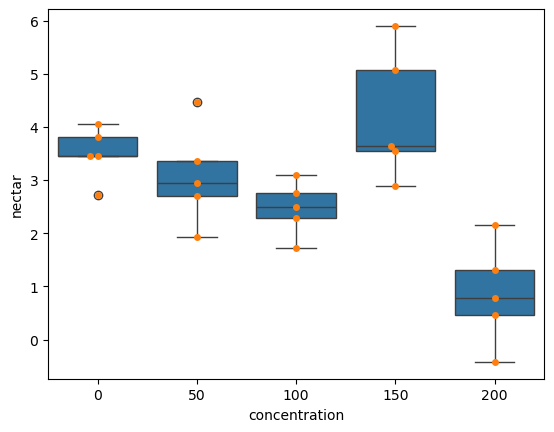

In [26]:
ax = sns.boxplot(data=nectar, y='nectar', x='concentration')
ax = sns.swarmplot(data=nectar, y='nectar', x='concentration');

- Perform an ANOVA "omnibus" test to determine the compatibility of the data with the null hypothesis that the means of all groups are the same. You can use either `anova_oneway` or a linear model, they will both give the same answer.

Note: if you use a linear model, make sure your formula explicitly makes `concentration` a categorical variable using `C(concentration)`.

<div class="alert alert-info">

Answer

- *F*<sub>2,19</sub> = 10.5
- *P* = 9.5 x 10<sup>-5</sup>
</div>

In [28]:
test = anova_oneway(nectar['nectar'], nectar['concentration'], use_var='equal')

print(f'degrees of freedom = {test.df}')
print(f'F-statistic = {test.statistic:.3g}')
print(f'P = {test.pvalue:.2g}')

degrees of freedom = (4.0, 20.0)
F-statistic = 10.5
P = 9.5e-05


In [29]:
formula = 'nectar ~ C(concentration)'
fit = ols(formula, nectar).fit()
fit.summary().tables[0]

Dep. Variable:,nectar,R-squared:,0.677
Model:,OLS,Adj. R-squared:,0.613
Method:,Least Squares,F-statistic:,10.49
Date:,"Thu, 29 Oct 2026",Prob (F-statistic):,9.54e-05
Time:,16:17:39,Log-Likelihood:,-29.387
No. Observations:,25,AIC:,68.77
Df Residuals:,20,BIC:,74.87
Df Model:,4,,
Covariance Type:,nonrobust,,


- Next perform a pairwise comparison between all pairs of concentrations. This involves:
1. Doing *t*-tests between all pairs of concentrations obtaining a raw *P*-value for each
2. Adjusting the raw *P*-values for multiple testing.

You may find it easier to copy, paste and modify the code from [workflow_iris_sepal_width.ipynb](workflow_iris_sepal_width.ipynb) 

In [31]:
results = {'comparison':[], 'p_raw':[]}

groups = nectar.groupby('concentration')['nectar']

for (c1, n1), (c2, n2) in combinations(groups, 2):
    results['comparison'].append((c1, c2))
    results['p_raw'].append(ttest_ind(n1, n2).pvalue)

results = pd.DataFrame(results)
results['p_adj'] = multipletests(results['p_raw'], method='holm')[1]

results.sort_values('p_adj')

,comparison,p_raw,p_adj
3,"(0, 200)",0.000594,0.005941
9,"(150, 200)",0.001359,0.012234
6,"(50, 200)",0.005894,0.047154
8,"(100, 200)",0.010517,0.073618
1,"(0, 100)",0.012808,0.076848
7,"(100, 150)",0.019785,0.098923
5,"(50, 150)",0.140716,0.562866
0,"(0, 50)",0.400057,0.715896
2,"(0, 150)",0.267813,0.715896
4,"(50, 100)",0.238632,0.715896


- What do you conclude about the effect of caffeine on bees feeding on nectar?

In [33]:
# output the summary table to get the estimated difference between 0 and 200μg caffeine
fit.summary().tables[1]

,coef,std err,t,P>|t|,[0.025,0.975]
Intercept,3.5000,0.392,8.930,0.000,2.682,4.318
C(concentration)[T.50],-0.4220,0.554,-0.761,0.455,-1.578,0.734
C(concentration)[T.100],-1.0300,0.554,-1.858,0.078,-2.186,0.126
C(concentration)[T.150],0.7120,0.554,1.285,0.214,-0.444,1.868
C(concentration)[T.200],-2.6440,0.554,-4.770,0.000,-3.800,-1.488


> Caffeine concentrations from 0 to 150 μg have no statistically significant effect on how much nectar is taken. At 200 μg caffeine, however, nectar taken falls by 2.6.g (95% CI: [1.5, 3.8] g) compared to 0 μg caffeine (*t*<sub>9</sub> = 4.8, *P*<sub>adj</sub> = 0.006). This suggests that caffeine is not used by plants to entice pollinators and that at concentrations above 200 μg, caffeine deters pollinators.

# Question 3: Cancer drug screening

<div>
<img src="Images/cancer_drugs.jpg" width='30%' title=""/>
</div>

IC50 is the concentration of a drug that reduces a biological response (e.g., cell viability, enzyme activity) by 50% compared to an untreated control.
It is inversely related to drug potency: A lower IC50 indicates a more potent drug (effective at lower concentrations).

The IC50 of 50 cancer drugs were measured in five breast cancer cell lines and five healthy breast cell lines. The goal is to find drugs that have significantly lower mean IC50 in drug cell lines compared to healthy cell lines.

The data are in the file `../Datasets/drug-screen.csv`. 

<div class="alert alert-warning">

Use the [workflow_gene_expression.ipynb](workflow_gene_expression.ipynb) notebook to help you answer this question.
</div>


---

- Read in the data and print it to see what it looks like.

In [38]:
screen = pd.read_csv('../Datasets/drug_screen.csv')
screen

,drug_name,cell_type,cell_line,ic50
0,Vemurafenib,cancer,MCF7,2.553
1,Vemurafenib,cancer,T47D,2.477
2,Vemurafenib,cancer,MDA-MB-231,2.418
3,Vemurafenib,cancer,BT474,2.952
4,Vemurafenib,cancer,SKBR3,2.374
...,...,...,...,...
495,Durvalumab,healthy,MCF10A,1.563
496,Durvalumab,healthy,HMEC,1.460
497,Durvalumab,healthy,MCF12A,1.543
498,Durvalumab,healthy,MCF10F,1.557


There are four variables:

1. `drug_name`: The name of the cancer drug. We need this to group IC50s together for each drug.
2. `cell_type`: whether the cell line is cancer cells or healthy cells
3. `cell_line`: the name of the cell line. This is not actually needed for the analysis.
4. `ic50`: the measured IC50 (in microMolar) of the drug in the cell line

---

- Use an appropriate graph to examine the distributions of IC50 in the two cell types. 

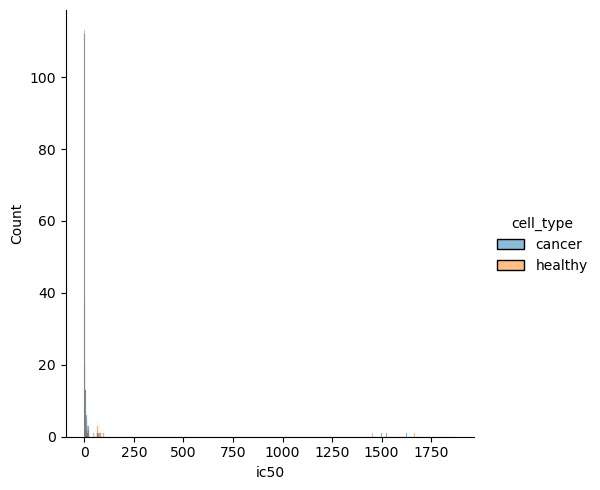

In [40]:
sns.displot(data=screen, x='ic50', hue='cell_type');

- Do the IC50s need log-transforming?

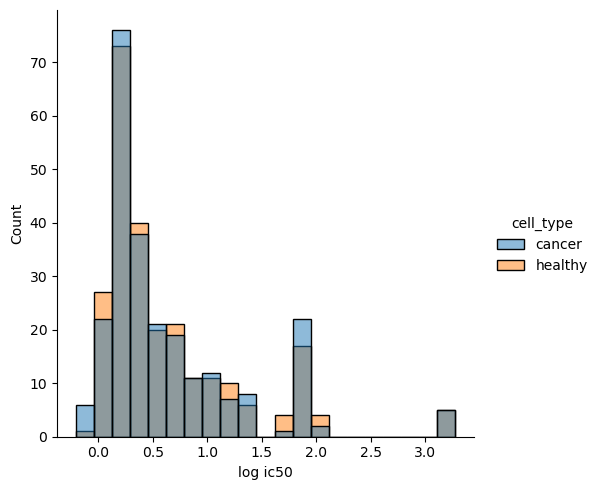

In [42]:
screen['log ic50'] = np.log10(screen['ic50'])
sns.displot(data=screen, x='log ic50', hue='cell_type');

- Perform *t*-tests on all drugs to compare the mean IC50 between cancer and healthy cell lines. Store the resulting raw *P*-values.

In [44]:
# set up a dictionary to save the results of the t-tests for all drugs
results = {'drug_name': [], 'p_raw': []}

# group the data into drugs
drugs = screen.groupby('drug_name')

# loop through each drug
for drug_name, drug in drugs:

    # get the log IC50s for the cancer and the healthy cell lines
    cancer_ic50 = drug[drug['cell_type'] == 'cancer']['log ic50']
    normal_ic50 = drug[drug['cell_type'] == 'healthy']['log ic50']

    # perform a t-test to compare the means of the cancer and healthy cell lines
    test = ttest_ind(cancer_ic50, normal_ic50)

    # store the drug_name and raw p-value from the t-test in the results dictionary
    results['drug_name'].append(drug_name)
    results['p_raw'].append(test.pvalue)

# convert the results dictionary to a pandas DataFrame for easier analysis
results_df = pd.DataFrame(results)

- Plot a histogram of the raw *P* values.

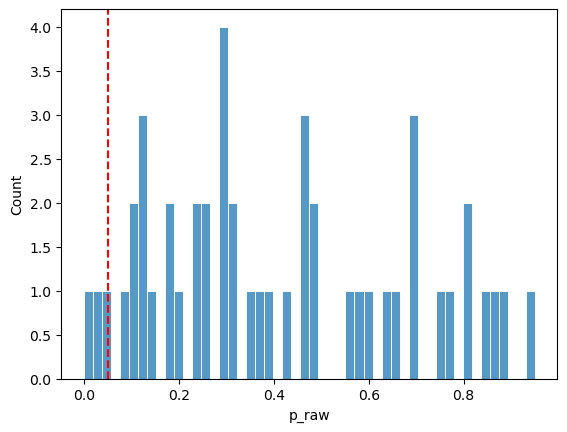

In [46]:
ax = sns.histplot(results_df['p_raw'], bins=50, edgecolor='white');
ax.axvline(0.05, color='red', linestyle='--');

- Print out the drugs with significant raw *P* values.

<div class="alert alert-info">
Answer:

Cabozantinib, Ribociclib and Tamoxifen
</div>

In [48]:
results_df.query('p_raw < 0.05').sort_values('p_raw')

,drug_name,p_raw
9,Cabozantinib,1.095785e-07
37,Ribociclib,3.575138e-02
42,Tamoxifen,4.268659e-02


- Adjust the raw *P*-values using the Benjamini-Hochberg method.


In [50]:
# send the raw p-values for adjustment using the Benjamini-Hochberg method
# and save the adjusted p-values into a new column in the dataframe
results_df['p_adj'] = multipletests(results_df['p_raw'], method='fdr_bh')[1]

- Print out the drugs with significant adjusted *P* values

<div class="alert alert-info">
Answer:

Cabozantinib, *P* = 5 x 10<sup>-6</sup>.
</div>

In [52]:
discoveries = results_df.query('p_adj < 0.05').sort_values('p_adj')
discoveries

,drug_name,p_raw,p_adj
9,Cabozantinib,1.095785e-07,0.000005
